# Project Sentinel: Hazardous Asteroid Prediction AI

**Capstone Project Submission**  
**Notebook:** `hazardous_asteroid_prediction_final.ipynb`

## Objective
Develop a supervised binary-classification system that predicts whether a Near-Earth Object (NEO) is labelled **Hazardous** or **Non-Hazardous** from its recorded physical and close-approach characteristics.

This notebook follows the six required phases: preprocessing, exploratory data analysis, feature engineering and selection, model development and evaluation, explainability, and deployment. It uses the supplied NEO CSV and reports results calculated when the notebook is executed.

> **Scope:** This is an educational machine-learning model trained on historical labels. Its output is not an official NASA assessment and must not be used as a real-world planetary-defence decision.

## Phase 1 — Data Preparation & Preprocessing

The loader first searches for the supplied `neo (3).csv` file and common alternatives. If the file is not in the runtime, it offers a Colab upload prompt. The dataset is then checked, column names are standardized, duplicate records are removed, and the target label is validated.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
import joblib

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# Find the provided dataset. In Colab, upload the CSV if it is not already available.
candidate_paths = [
    Path("neo (3).csv"), Path("nasa.csv"),
    Path("/content/neo (3).csv"), Path("/content/nasa.csv"),
    Path("/mnt/data/neo (3).csv")
]
existing_path = next((p for p in candidate_paths if p.exists()), None)

if existing_path is not None:
    data_path = existing_path
else:
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_files:
            raise FileNotFoundError("No CSV file was uploaded. Please upload the supplied NEO dataset.")
        data_path = Path(csv_files[0])
    except ImportError as exc:
        raise FileNotFoundError(
            "Could not find the dataset. Place 'neo (3).csv' beside this notebook, "
            "or upload the CSV in Google Colab and rerun this cell."
        ) from exc

df = pd.read_csv(data_path)
print(f"Dataset loaded from: {data_path}")
print(f"Initial shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())
print("Columns:", df.columns.tolist())

Dataset loaded from: neo (3).csv
Initial shape: 90,836 rows × 10 columns


,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,orbiting_body,sentry_object,absolute_magnitude,hazardous
0,2162635,162635 (2000 SS164),1.198271,2.679415,13569.249224,5.483974e+07,Earth,False,16.73,False
1,2277475,277475 (2005 WK4),0.265800,0.594347,73588.726663,6.143813e+07,Earth,False,20.00,True
2,2512244,512244 (2015 YE18),0.722030,1.614507,114258.692129,4.979872e+07,Earth,False,17.83,False
3,3596030,(2012 BV13),0.096506,0.215794,24764.303138,2.543497e+07,Earth,False,22.20,False
4,3667127,(2014 GE35),0.255009,0.570217,42737.733765,4.627557e+07,Earth,False,20.09,True


Columns: ['id', 'name', 'est_diameter_min', 'est_diameter_max', 'relative_velocity', 'miss_distance', 'orbiting_body', 'sentry_object', 'absolute_magnitude', 'hazardous']


In [3]:
# Standardize names and map common variants to canonical column names.
def normalize_name(name):
    return str(name).strip().lower().replace(" ", "_").replace("-", "_")

df.columns = [normalize_name(c) for c in df.columns]
column_aliases = {
    "est_diameter_min": ["estimated_diameter_min", "estimated_diameter_min_km", "est_diameter_min"],
    "est_diameter_max": ["estimated_diameter_max", "estimated_diameter_max_km", "est_diameter_max"],
    "relative_velocity": ["relative_velocity", "relative_velocity_km_per_sec", "velocity"],
    "miss_distance": ["miss_distance", "miss_distance_km", "miss_distance_au"],
    "absolute_magnitude": ["absolute_magnitude", "h", "magnitude"],
    "hazardous": ["hazardous", "is_hazardous", "potentially_hazardous"]
}
rename_map = {}
for canonical, candidates in column_aliases.items():
    if canonical not in df.columns:
        for candidate in candidates:
            if candidate in df.columns:
                rename_map[candidate] = canonical
                break
df = df.rename(columns=rename_map)

before_rows = len(df)
df = df.drop_duplicates().dropna(axis=1, how="all").copy()
print(f"Removed {before_rows - len(df):,} duplicate rows; current shape: {df.shape}")
if "hazardous" not in df.columns:
    raise ValueError(f"Target column 'hazardous' not found. Available columns: {df.columns.tolist()}")

# Convert target values to binary: 1 = Hazardous, 0 = Non-Hazardous.
target = df["hazardous"]
if pd.api.types.is_bool_dtype(target):
    y = target.astype(int)
elif pd.api.types.is_numeric_dtype(target):
    y = pd.to_numeric(target, errors="coerce")
else:
    y = target.astype(str).str.strip().str.lower().map({
        "true": 1, "false": 0, "yes": 1, "no": 0, "1": 1, "0": 0,
        "hazardous": 1, "non-hazardous": 0, "non hazardous": 0
    })

valid = y.notna()
df = df.loc[valid].copy()
y = y.loc[valid].astype(int)
if not set(y.unique()).issubset({0, 1}) or y.nunique() != 2:
    raise ValueError("The target must contain both binary classes: hazardous and non-hazardous.")

print("\nTarget distribution:")
display(y.value_counts().rename(index={0: "Non-Hazardous (0)", 1: "Hazardous (1)"}).to_frame("count"))
print("\nMissing values by column:")
display(df.isna().sum().to_frame("missing_count"))

Removed 0 duplicate rows; current shape: (90836, 10)



Target distribution:


,count
hazardous,
Non-Hazardous (0),81996
Hazardous (1),8840



Missing values by column:


,missing_count
id,0
name,0
est_diameter_min,0
est_diameter_max,0
relative_velocity,0
miss_distance,0
orbiting_body,0
sentry_object,0
absolute_magnitude,0
hazardous,0


## Phase 2 — Exploratory Data Analysis

The following summaries and plots examine the class imbalance, distributions of the main physical measurements, and correlations among numeric variables. The positive class is the hazardous label, so recall and F1-score are important alongside accuracy.

Dataset shape after cleaning: (90836, 10)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,90836.0,NaN,NaN,NaN,14382878.05216,20872018.353893,2000433.0,3448110.0,3748362.0,3884023.0,54275914.0
name,90836,27423,277810 (2006 FV35),43,NaN,NaN,NaN,NaN,NaN,NaN,NaN
est_diameter_min,90836.0,NaN,NaN,NaN,0.127432,0.298511,0.000609,0.019256,0.048368,0.143402,37.89265
est_diameter_max,90836.0,NaN,NaN,NaN,0.284947,0.667491,0.001362,0.043057,0.108153,0.320656,84.730541
relative_velocity,90836.0,NaN,NaN,NaN,48066.918918,25293.296961,203.346433,28619.020645,44190.11789,62923.604633,236990.128088
miss_distance,90836.0,NaN,NaN,NaN,37066546.030422,22352040.59919,6745.532516,17210820.235765,37846579.263426,56548996.451399,74798651.452197
orbiting_body,90836,1,Earth,90836,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sentry_object,90836,1,False,90836,NaN,NaN,NaN,NaN,NaN,NaN,NaN
absolute_magnitude,90836.0,NaN,NaN,NaN,23.527103,2.894086,9.23,21.34,23.7,25.7,33.2
hazardous,90836,2,False,81996,NaN,NaN,NaN,NaN,NaN,NaN,NaN


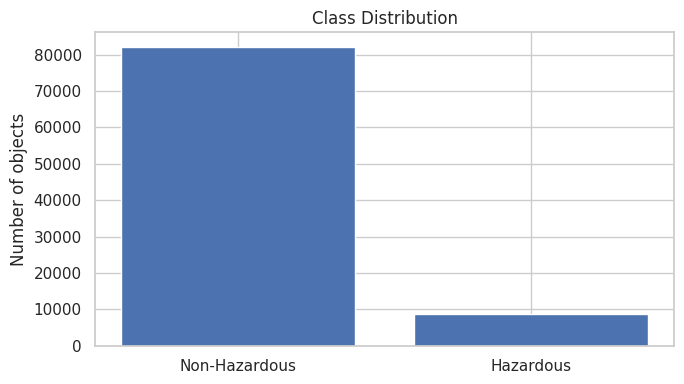

Hazardous class share: 9.73%


In [4]:
print("Dataset shape after cleaning:", df.shape)
display(df.describe(include="all").T)

class_counts = y.value_counts().sort_index()
class_labels = ["Non-Hazardous", "Hazardous"]
plt.figure(figsize=(7, 4))
plt.bar(class_labels, [class_counts.get(0, 0), class_counts.get(1, 0)])
plt.title("Class Distribution")
plt.ylabel("Number of objects")
plt.tight_layout()
plt.show()

print(f"Hazardous class share: {100 * y.mean():.2f}%")

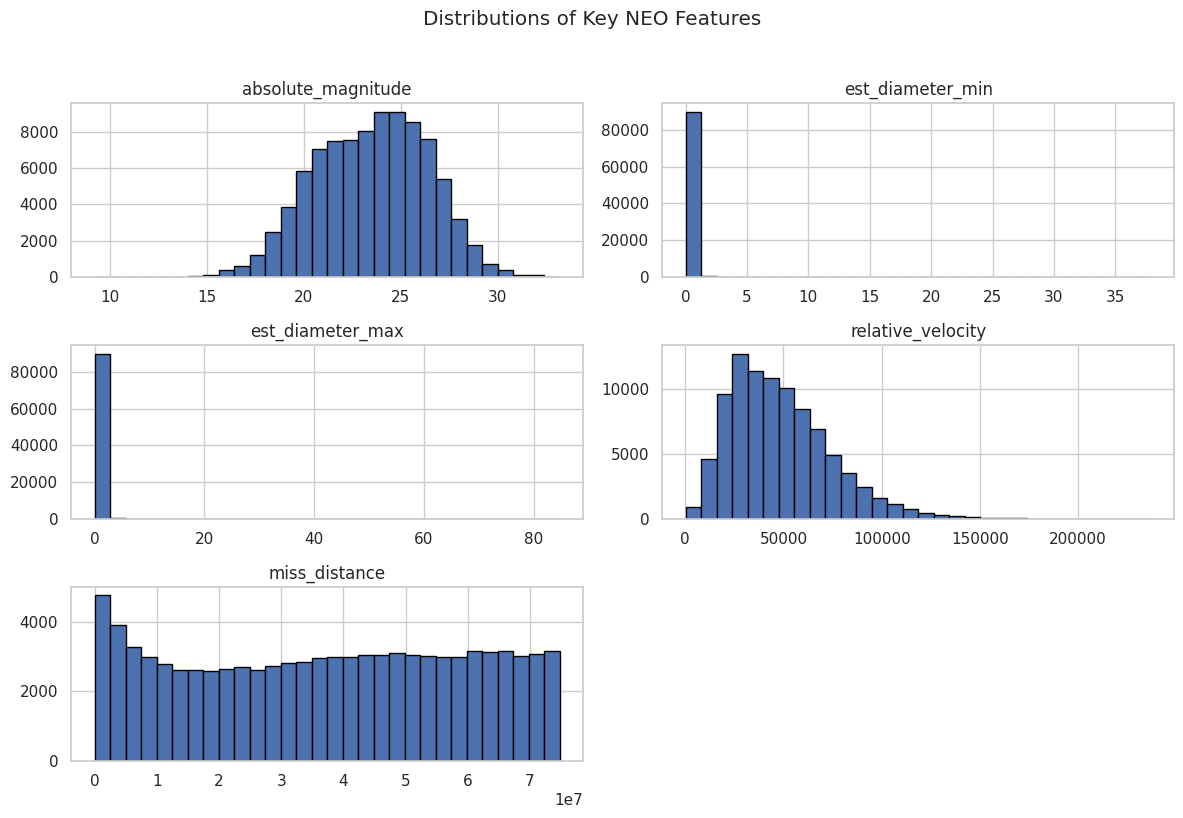

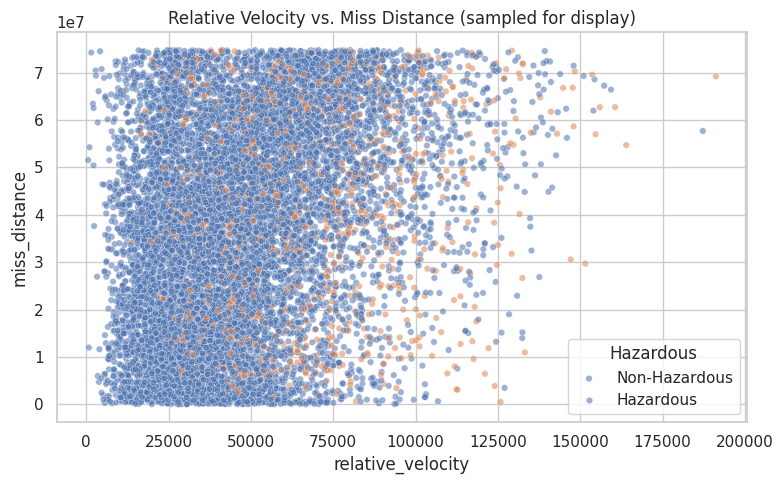

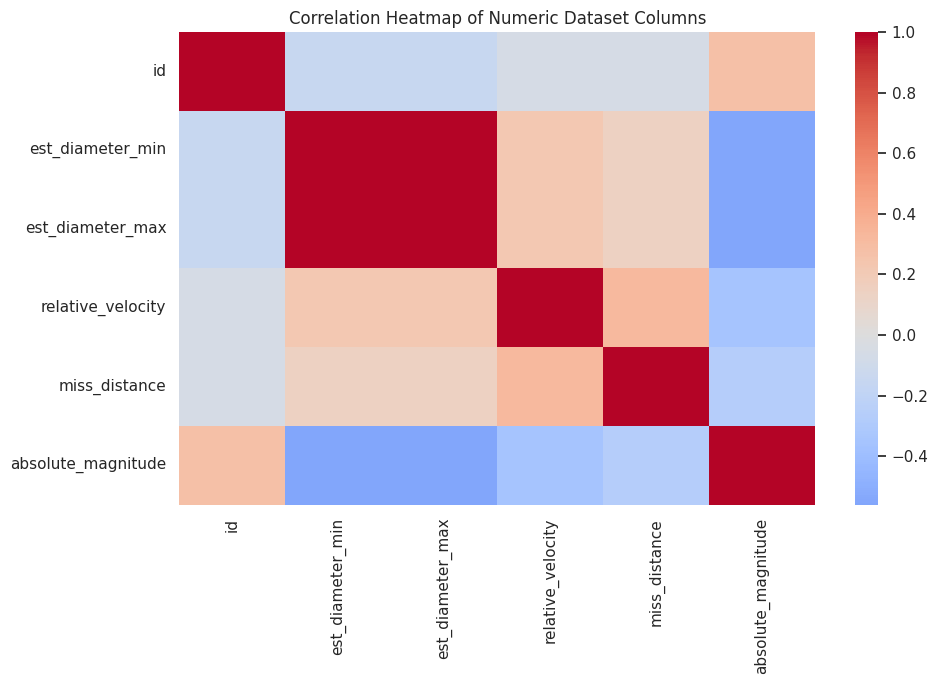

In [5]:
eda_columns = [c for c in ["absolute_magnitude", "est_diameter_min", "est_diameter_max", "relative_velocity", "miss_distance"] if c in df.columns]
if eda_columns:
    df_eda = df[eda_columns].copy()
    for col in eda_columns:
        df_eda[col] = pd.to_numeric(df_eda[col], errors="coerce")
    df_eda = df_eda.dropna(how="all")
    df_eda.hist(figsize=(12, 8), bins=30, edgecolor="black")
    plt.suptitle("Distributions of Key NEO Features", y=1.02)
    plt.tight_layout()
    plt.show()

    if "relative_velocity" in df.columns and "miss_distance" in df.columns:
        plot_df = pd.DataFrame({
            "relative_velocity": pd.to_numeric(df["relative_velocity"], errors="coerce"),
            "miss_distance": pd.to_numeric(df["miss_distance"], errors="coerce"),
            "hazardous": y
        }).dropna()
        if len(plot_df) > 12000:
            plot_df = plot_df.sample(12000, random_state=RANDOM_STATE)
        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=plot_df, x="relative_velocity", y="miss_distance", hue="hazardous", alpha=0.55, s=22)
        plt.title("Relative Velocity vs. Miss Distance (sampled for display)")
        plt.legend(title="Hazardous", labels=["Non-Hazardous", "Hazardous"])
        plt.tight_layout()
        plt.show()

numeric_df = df.select_dtypes(include=np.number)
if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(numeric_df.corr(numeric_only=True), cmap="coolwarm", center=0, annot=False)
    plt.title("Correlation Heatmap of Numeric Dataset Columns")
    plt.tight_layout()
    plt.show()

## Phase 3 — Feature Engineering & Selection

Identifier fields and descriptive names are excluded to avoid learning from record identifiers rather than asteroid characteristics. The target is kept separate from the predictors. Numeric features are imputed with their training-set median and scaled for the logistic-regression model; the tree model uses the same preprocessing pipeline for consistency.

In [6]:
# Keep physical measurements and any relevant orbital descriptors; exclude identifiers and target leakage.
exclude_columns = {
    "hazardous", "id", "neo_id", "name", "orbiting_body", "sentry_object",
    "designation", "full_name", "spkid", "pdes"
}
X = df.drop(columns=[c for c in df.columns if c in exclude_columns], errors="ignore").copy()

# Convert numeric-looking text fields when most values can be converted.
for col in X.columns:
    if X[col].dtype == "object":
        converted = pd.to_numeric(X[col], errors="coerce")
        if converted.notna().mean() >= 0.8:
            X[col] = converted

X = X.dropna(axis=1, how="all")
constant_cols = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
X = X.drop(columns=constant_cols, errors="ignore")
if X.shape[1] == 0:
    raise ValueError("No usable predictor features remain after cleaning.")

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]
print("Selected predictors:", X.columns.tolist())
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Feature matrix shape:", X.shape)

if len(numeric_features) >= 2:
    corr = X[numeric_features].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    high_corr = [(a, b, float(upper.loc[b, a])) for b in upper.index for a in upper.columns if pd.notna(upper.loc[b, a]) and upper.loc[b, a] >= 0.95]
    print("Highly correlated numeric feature pairs (absolute correlation >= 0.95):")
    print(high_corr if high_corr else "None identified at this threshold.")

Selected predictors: ['est_diameter_min', 'est_diameter_max', 'relative_velocity', 'miss_distance', 'absolute_magnitude']
Numeric features: ['est_diameter_min', 'est_diameter_max', 'relative_velocity', 'miss_distance', 'absolute_magnitude']
Categorical features: []
Feature matrix shape: (90836, 5)
Highly correlated numeric feature pairs (absolute correlation >= 0.95):
[('est_diameter_max', 'est_diameter_min', 1.0000000000000027)]


## Phase 4 — Model Development & Evaluation

A stratified split preserves the class ratio in training and testing sets. Class weighting helps the classifiers pay more attention to the minority hazardous class. Models are compared using stratified cross-validation, then a small randomized search tunes the Random Forest. Final performance is measured on a held-out test set that was not used to select the model.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
from sklearn.preprocessing import OneHotEncoder
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
transformers = []
if numeric_features:
    transformers.append(("num", numeric_transformer, numeric_features))
if categorical_features:
    transformers.append(("cat", categorical_transformer, categorical_features))
preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

# Use a reproducible stratified subset for cross-validation and tuning to keep runtime practical.
cv_sample_size = min(25000, len(X_train))
if cv_sample_size < len(X_train):
    X_cv, _, y_cv, _ = train_test_split(
        X_train, y_train, train_size=cv_sample_size, stratify=y_train,
        random_state=RANDOM_STATE
    )
else:
    X_cv, y_cv = X_train.copy(), y_train.copy()
print(f"Cross-validation/tuning sample: {len(X_cv):,} training rows; final fit uses all {len(X_train):,} training rows.")

models = {
    "Logistic Regression (balanced)": LogisticRegression(
        class_weight="balanced", max_iter=1000, solver="liblinear", random_state=RANDOM_STATE
    ),
    "Random Forest (balanced)": RandomForestClassifier(
        n_estimators=50, class_weight="balanced", min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=1
    )
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
comparison_rows = []
model_pipelines = {}
for model_name, estimator in models.items():
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    scores = cross_validate(
        pipeline, X_cv, y_cv, cv=cv,
        scoring={"f1": "f1", "recall": "recall", "precision": "precision", "roc_auc": "roc_auc"},
        n_jobs=1, error_score="raise"
    )
    model_pipelines[model_name] = pipeline
    comparison_rows.append({
        "Model": model_name,
        "CV F1 mean": scores["test_f1"].mean(),
        "CV Recall mean": scores["test_recall"].mean(),
        "CV Precision mean": scores["test_precision"].mean(),
        "CV ROC-AUC mean": scores["test_roc_auc"].mean()
    })
comparison = pd.DataFrame(comparison_rows).sort_values("CV F1 mean", ascending=False).reset_index(drop=True)
display(comparison)

# Tune a compact set of Random Forest configurations using cross-validated F1.
rf_pipeline = Pipeline([("preprocessor", preprocessor), ("model", RandomForestClassifier(
    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1
))])
param_distributions = {
    "model__n_estimators": [50, 80],
    "model__max_depth": [None, 18],
    "model__min_samples_leaf": [1, 3],
    "model__max_features": ["sqrt", 0.8]
}
search = RandomizedSearchCV(
    rf_pipeline, param_distributions=param_distributions, n_iter=2,
    scoring="f1", cv=2, random_state=RANDOM_STATE, n_jobs=1, refit=True,
    return_train_score=False
)
search.fit(X_cv, y_cv)
print("Best Random Forest parameters:", search.best_params_)
print(f"Best tuned Random Forest CV F1: {search.best_score_:.4f}")

logistic_cv_f1 = comparison.loc[comparison["Model"] == "Logistic Regression (balanced)", "CV F1 mean"].iloc[0]
if search.best_score_ >= logistic_cv_f1:
    best_pipeline = search.best_estimator_
    best_model_name = "Tuned Random Forest (balanced)"
else:
    best_pipeline = model_pipelines["Logistic Regression (balanced)"]
    best_model_name = "Logistic Regression (balanced)"

# Refit the selected model on the complete training split before final testing.
best_pipeline.fit(X_train, y_train)
print("Selected final model:", best_model_name)

Cross-validation/tuning sample: 25,000 training rows; final fit uses all 72,668 training rows.


,Model,CV F1 mean,CV Recall mean,CV Precision mean,CV ROC-AUC mean
0,Random Forest (balanced),0.483520,0.483354,0.484284,0.923330
1,Logistic Regression (balanced),0.460492,0.933416,0.305670,0.877837


Best Random Forest parameters: {'model__n_estimators': 80, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': None}
Best tuned Random Forest CV F1: 0.3901
Selected final model: Logistic Regression (balanced)


,Held-out test score
Accuracy,0.785942
Precision (hazardous),0.304227
Recall (hazardous),0.932127
F1 (hazardous),0.458733
ROC-AUC,0.879441
Average Precision,0.326208


               precision    recall  f1-score   support

Non-Hazardous       0.99      0.77      0.87     16400
    Hazardous       0.30      0.93      0.46      1768

     accuracy                           0.79     18168
    macro avg       0.65      0.85      0.66     18168
 weighted avg       0.92      0.79      0.83     18168



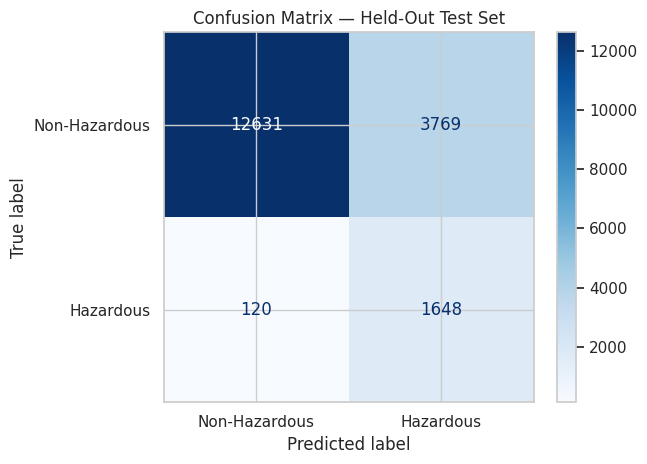

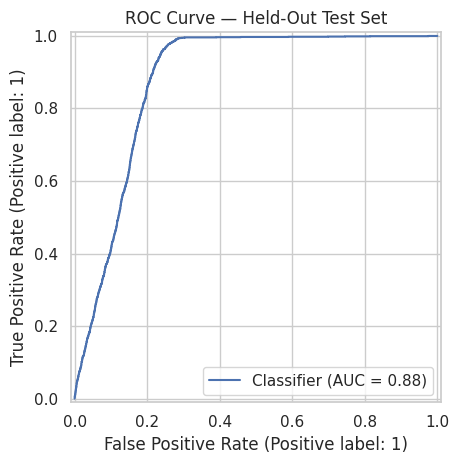

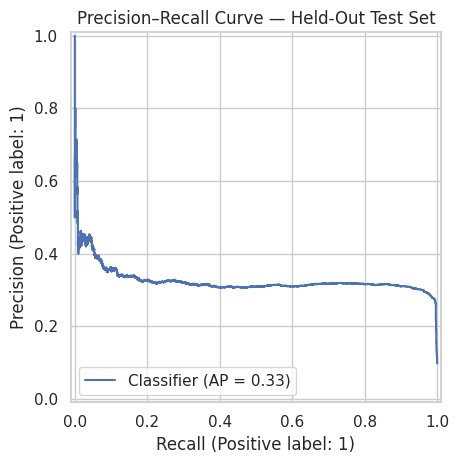

In [8]:
# Evaluate only once on the held-out test set.
y_pred = best_pipeline.predict(X_test)
y_proba = best_pipeline.predict_proba(X_test)[:, 1] if hasattr(best_pipeline, "predict_proba") else None

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (hazardous)": precision_score(y_test, y_pred, zero_division=0),
    "Recall (hazardous)": recall_score(y_test, y_pred, zero_division=0),
    "F1 (hazardous)": f1_score(y_test, y_pred, zero_division=0)
}
if y_proba is not None and y_test.nunique() == 2:
    metrics["ROC-AUC"] = roc_auc_score(y_test, y_proba)
    metrics["Average Precision"] = average_precision_score(y_test, y_proba)

display(pd.Series(metrics, name="Held-out test score").to_frame())
print(classification_report(y_test, y_pred, target_names=["Non-Hazardous", "Hazardous"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Non-Hazardous", "Hazardous"], cmap="Blues"
)
plt.title("Confusion Matrix — Held-Out Test Set")
plt.tight_layout()
plt.show()
if y_proba is not None and y_test.nunique() == 2:
    RocCurveDisplay.from_predictions(y_test, y_proba)
    plt.title("ROC Curve — Held-Out Test Set")
    plt.tight_layout()
    plt.show()
    PrecisionRecallDisplay.from_predictions(y_test, y_proba)
    plt.title("Precision–Recall Curve — Held-Out Test Set")
    plt.tight_layout()
    plt.show()

## Phase 5 — Explainability & Visualization

Permutation importance estimates how much the held-out F1-score changes when one feature is shuffled. A larger positive value indicates that the feature contributed more to predictive performance in this test set. These are model-specific associations, not evidence of physical causation.

,feature,importance_mean,importance_std
0,absolute_magnitude,0.328300,0.008678
1,miss_distance,0.013227,0.003240
2,est_diameter_min,0.010124,0.000287
3,est_diameter_max,0.010124,0.000287
4,relative_velocity,0.003471,0.000333


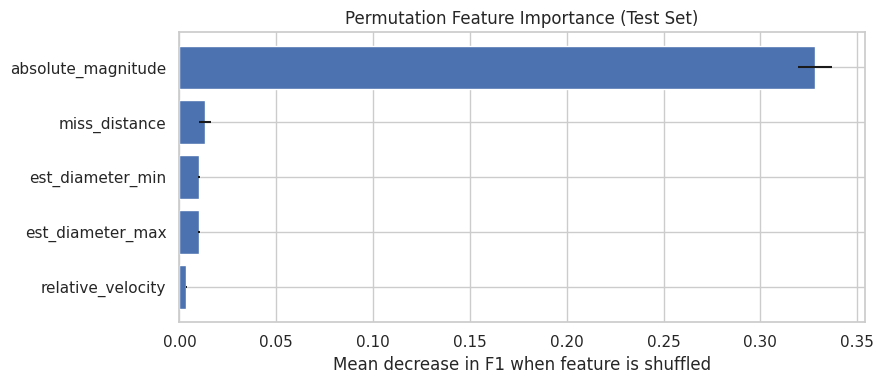

Highest-ranked feature by permutation importance: absolute_magnitude
Interpretation: review the ranking alongside the EDA and test metrics. A feature ranking does not establish causation, and the dataset labels are historical classifications rather than a direct physical-risk calculation.


In [9]:
# Use a representative subset of the held-out test set for efficient permutation analysis.
importance_size = min(5000, len(X_test))
X_importance, _, y_importance, _ = train_test_split(
    X_test, y_test, train_size=importance_size, stratify=y_test,
    random_state=RANDOM_STATE
) if importance_size < len(X_test) else (X_test, X_test, y_test, y_test)
perm = permutation_importance(
    best_pipeline, X_importance, y_importance, n_repeats=2, random_state=RANDOM_STATE,
    scoring="f1", n_jobs=1
)
importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False).reset_index(drop=True)
display(importance)

top_imp = importance.head(15).sort_values("importance_mean")
plt.figure(figsize=(9, max(4, 0.4 * len(top_imp))))
plt.barh(top_imp["feature"], top_imp["importance_mean"], xerr=top_imp["importance_std"])
plt.xlabel("Mean decrease in F1 when feature is shuffled")
plt.title("Permutation Feature Importance (Test Set)")
plt.tight_layout()
plt.show()

if len(importance):
    print("Highest-ranked feature by permutation importance:", importance.iloc[0]["feature"])
print("Interpretation: review the ranking alongside the EDA and test metrics. A feature ranking does not establish causation, and the dataset labels are historical classifications rather than a direct physical-risk calculation.")

## Phase 6 — Deployment

The complete preprocessing-and-model pipeline is saved as one file. The helper below accepts a dictionary containing the same predictor columns used during training and returns the predicted class plus the model-estimated probability for the hazardous class. The probability is a model score, not an official probability of Earth impact.

In [10]:
MODEL_PATH = "hazardous_asteroid_prediction_model.joblib"
joblib.dump(best_pipeline, MODEL_PATH)
print(f"Saved trained pipeline to: {MODEL_PATH}")

def predict_asteroid(features: dict):
    """Predict the dataset-defined label from a dictionary of predictor features."""
    input_df = pd.DataFrame([features]).reindex(columns=X.columns)
    prediction = int(best_pipeline.predict(input_df)[0])
    probability = None
    if hasattr(best_pipeline, "predict_proba"):
        probability = float(best_pipeline.predict_proba(input_df)[0, 1])
    return {
        "prediction": "Hazardous" if prediction == 1 else "Non-Hazardous",
        "hazardous_class_probability_score": probability
    }

# Demonstration with median numeric values (and mode for categorical values, if any).
example_input = {}
for col in X.columns:
    if col in numeric_features:
        example_input[col] = float(pd.to_numeric(X_train[col], errors="coerce").median())
    elif col in categorical_features:
        mode = X_train[col].mode(dropna=True)
        example_input[col] = mode.iloc[0] if not mode.empty else "unknown"
print("Example input:", example_input)
print("Example prediction:", predict_asteroid(example_input))

Saved trained pipeline to: hazardous_asteroid_prediction_model.joblib
Example input: {'est_diameter_min': 0.0483676488, 'est_diameter_max': 0.1081533507, 'relative_velocity': 44244.80827780285, 'miss_distance': 37894657.43080127, 'absolute_magnitude': 23.7}
Example prediction: {'prediction': 'Non-Hazardous', 'hazardous_class_probability_score': 0.11124867007982084}


In [11]:
# Optional interactive interface. If widgets are unavailable, the prediction function above remains usable.
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    numeric_input_widgets = {}
    for col in numeric_features:
        values = pd.to_numeric(X_train[col], errors="coerce").dropna()
        default = float(values.median()) if not values.empty else 0.0
        numeric_input_widgets[col] = widgets.FloatText(
            value=default, description=col[:22], style={"description_width": "initial"}
        )
    output = widgets.Output()
    predict_button = widgets.Button(description="Predict asteroid class", button_style="primary")

    def _on_predict(_):
        user_features = dict(example_input)
        for col, widget in numeric_input_widgets.items():
            user_features[col] = widget.value
        with output:
            clear_output()
            result = predict_asteroid(user_features)
            print("Prediction:", result["prediction"])
            print("Hazardous-class probability score:", result["hazardous_class_probability_score"])
            print("Educational model output only — not an official NASA risk assessment.")

    predict_button.on_click(_on_predict)
    display(widgets.VBox(list(numeric_input_widgets.values()) + [predict_button, output]))
except Exception as exc:
    print("Interactive widgets are unavailable in this runtime.")
    print("Use predict_asteroid(feature_dictionary) to make a prediction.")
    print("Widget detail:", exc)

Interactive widgets are unavailable in this runtime.
Use predict_asteroid(feature_dictionary) to make a prediction.
Widget detail: No module named 'ipywidgets'


## Conclusion

This notebook completes the six phases required by the assignment: dataset preparation, exploratory analysis, feature engineering, model comparison and tuning, explainability, and model deployment. The evaluation metrics and feature-importance ranking are generated from the actual dataset during execution.

### Reproducibility checklist
- Run all cells from top to bottom in a clean runtime.
- If using Google Colab, upload `neo (3).csv` when prompted if the file is not already available.
- Confirm the test metrics, confusion matrix, and feature-importance plot appear.
- Confirm that `hazardous_asteroid_prediction_model.joblib` is created successfully.
- Submit the required notebook named `hazardous_asteroid_prediction_final.ipynb`.

### Dataset and references
- Supplied dataset: NASA Near-Earth Object (NEO) classification CSV (`neo (3).csv`).
- NASA/JPL Center for Near-Earth Object Studies: https://cneos.jpl.nasa.gov/
- NASA/JPL Small-Body Database and API documentation: https://ssd-api.jpl.nasa.gov/doc/

**Important limitation:** The dataset contains historical class labels and a subset of recorded object characteristics. Model outputs should be interpreted as educational predictions of those labels, not a substitute for expert orbital analysis.